Dataset shape: (150, 2)


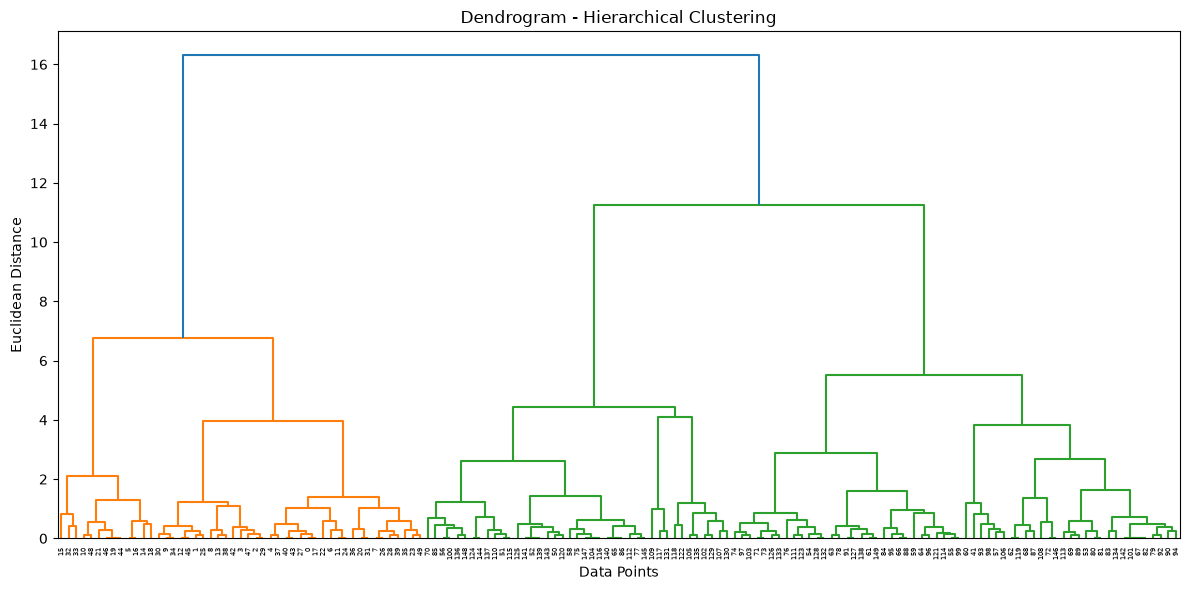

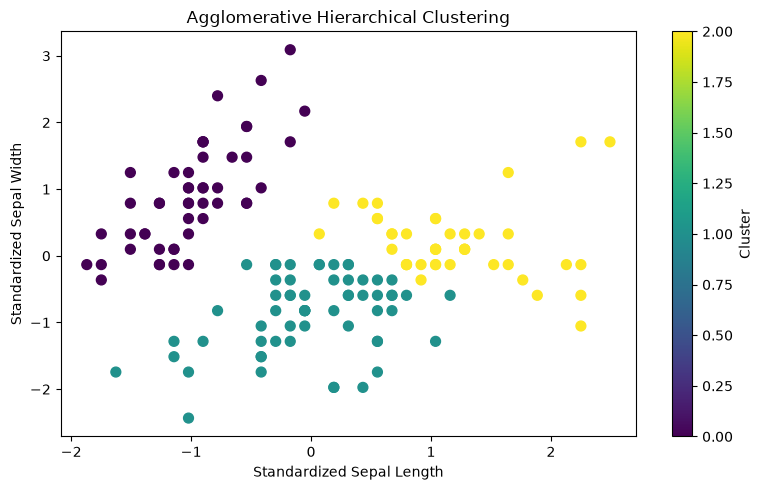


Cluster assignments:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 2 2 2 1 1 1 2 1 2 1 1 1 1 1 1 2 1 1 1 1 2 1 1 1
 1 2 1 2 1 1 1 1 1 1 1 2 2 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 1 2 2 1 2 1 2 2
 1 2 1 1 2 2 2 2 1 2 1 2 1 2 2 1 1 1 2 2 2 1 1 1 2 2 2 1 2 2 2 1 2 2 2 1 2
 2 1]

First 10 data points and their clusters:
Data Point: 0 Cluster: 0
Data Point: 1 Cluster: 0
Data Point: 2 Cluster: 0
Data Point: 3 Cluster: 0
Data Point: 4 Cluster: 0
Data Point: 5 Cluster: 0
Data Point: 6 Cluster: 0
Data Point: 7 Cluster: 0
Data Point: 8 Cluster: 0
Data Point: 9 Cluster: 0


In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

iris = load_iris()
X = iris.data[:, :2] 

print("Dataset shape:", X.shape)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(linked)
plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

clusters = model.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)

plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.title("Agglomerative Hierarchical Clustering")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()


print("\nCluster assignments:")
print(clusters)

print("\nFirst 10 data points and their clusters:")

for i in range(10):
    print("Data Point:", i, "Cluster:", clusters[i])

Dataset shape: (150, 2)
Data standardized successfully!


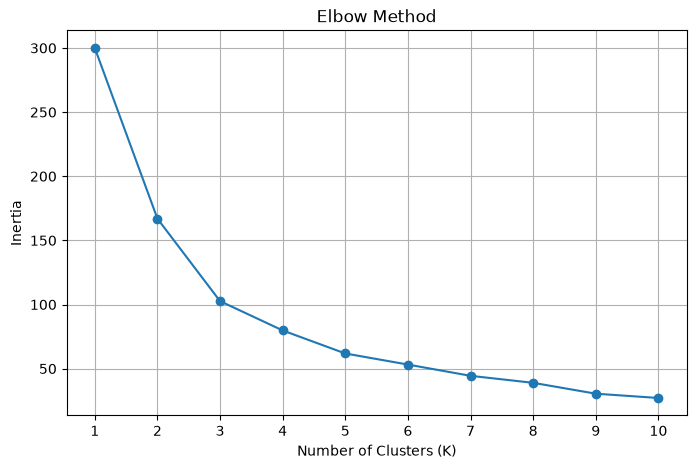

Elbow Method graph displayed!
K-Means clustering completed successfully!


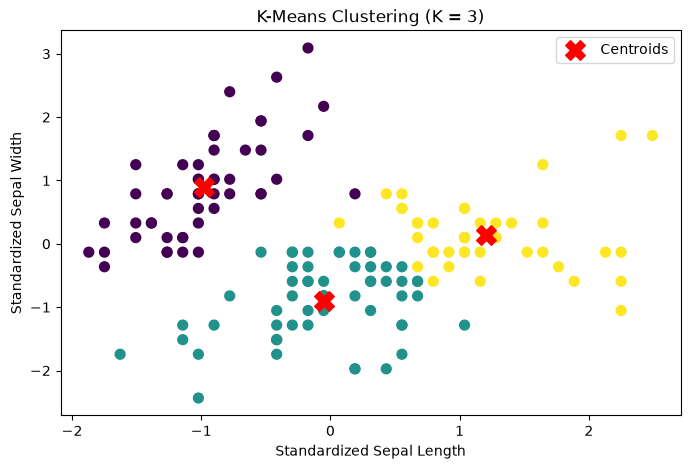


First 10 cluster assignments:
[0 0 0 0 0 0 0 0 0 0]

Total number of clusters: 3


In [3]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X = iris.data[:, :2] 

print("Dataset shape:", X.shape)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data standardized successfully!")

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

print("Elbow Method graph displayed!")

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed successfully!")

plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200,
    color='red',
    label='Centroids'
)

plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.title("K-Means Clustering (K = 3)")
plt.legend()
plt.show()

print("\nFirst 10 cluster assignments:")
print(clusters[:10])

print("\nTotal number of clusters:", len(set(clusters)))